# Proyecto 2: Fine-tuning para tareas de PLN

Curso de Procesamiento de Lenguaje Natural, Universidad de Antioquia.

## Introducción

En este proyecto hago fine-tuning de tres modelos preentrenados de Hugging Face, uno para cada tipo de problema de PLN que pide el enunciado.

Un modelo preentrenado ya aprendió bastante sobre el idioma porque se entrenó con grandes cantidades de texto sin etiquetas, con tareas como adivinar palabras tapadas o reconstruir texto dañado. Hacer fine-tuning es seguir entrenando ese modelo con un dataset etiquetado mucho más pequeño para que aprenda una tarea concreta. En clasificación y en etiquetado se le agrega una capa de salida nueva para la tarea; en seq2seq se reutiliza la parte que genera texto, que ya viene en el modelo. Se entrenan todos los pesos con un learning rate bajo para no dañar lo que el modelo ya sabía.

La ventaja es que no hay que aprender el idioma desde cero. Con unos miles de ejemplos y minutos u horas de GPU se llega a resultados que entrenando desde cero pedirían muchos más datos y tiempo.

| Tarea | Tipo de problema | Dataset | Idioma | Modelo | Métrica principal |
|---|---|---|---|---|---|
| 1 | Clasificación de secuencias: emoción de un tuit (6 clases) | `dair-ai/emotion` | inglés | `distilbert/distilbert-base-uncased` | F1 macro |
| 2 | Etiquetado de secuencias: reconocimiento de entidades (NER) | `BramVanroy/conll2002` (config `es`) | español | `dccuchile/bert-base-spanish-wwm-cased` (BETO) | F1 de seqeval |
| 3 | Sequence-to-sequence: resumen de diálogos | `knkarthick/dialogsum` | inglés | `facebook/bart-base` | ROUGE |

El notebook está organizado así:

- Sección 0: configuración del entorno (instalación en Colab, login en Hugging Face, dispositivo, semilla y funciones comunes).
- Tareas 1, 2 y 3, cada una con las mismas cinco partes: x.1 descripción del dataset, x.2 análisis exploratorio, x.3 búsqueda de hiperparámetros sobre una muestra, x.4 entrenamiento con la data completa y x.5 evaluación del mejor modelo.
- Conclusiones.

Cada tarea empieza con una celda de constantes (dataset y modelo) y se puede correr sola, siempre que antes se haya corrido la sección 0. El entrenamiento lo hago en Colab con una GPU T4. Por qué escogí estos datasets y modelos está en `docs/seleccion_datasets.md` del repositorio.

## 0. Configuración del entorno

El notebook corre igual en Colab y en local. Para correrlo:

- En Colab: Entorno de ejecución > Cambiar tipo de entorno de ejecución > GPU T4. El token de Hugging Face va en los Secrets de Colab con el nombre `HF_TOKEN`, y los checkpoints quedan en Google Drive.
- En local: `uv sync` en la raíz del repo, el kernel `proyecto2-nlp` y el token en el archivo `.env`.

La primera celda detecta dónde está corriendo. En Colab instala lo que falta con las mismas versiones del `uv.lock` del repo y deja el torch que trae Colab, que ya viene con CUDA. En local no instala nada, porque las dependencias salen de `uv sync`. La segunda celda monta Drive si está en Colab, lee el token de Hugging Face, escoge el dispositivo y fija la semilla. La tercera tiene funciones que uso en los tres análisis exploratorios.

In [1]:
# Detección del entorno e instalación (solo en Colab)
import importlib.metadata as md
import os
import re
import subprocess
import sys
import tempfile

IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

# Mismas versiones del uv.lock. Si se actualiza el lock hay que cambiarlas aquí;
# scripts/check_env.py avisa cuando no coinciden.
COLAB_PINS = {
    "transformers": "5.23.0",
    "tokenizers": "0.23.3",
    "huggingface-hub": "2.4.0",
    "datasets": "5.2.0",
    "evaluate": "0.4.6",
    "accelerate": "1.16.0",
    "seqeval": "1.2.2",
    "sacrebleu": "2.6.0",
    "rouge-score": "0.1.2",
}


def _norm(nombre):
    return re.sub(r"[-_.]+", "-", nombre).lower()


def _instaladas():
    return {_norm(d.metadata["Name"]): d.version for d in md.distributions()}


if IN_COLAB:
    antes = _instaladas()
    pendientes = [f"{p}=={v}" for p, v in COLAB_PINS.items() if antes.get(_norm(p)) != v]
    assert "torch" in antes, "Colab debería traer torch preinstalado"
    if pendientes:
        # El constraint deja torch exactamente como viene en Colab: si algo pidiera
        # otra versión, pip falla en vez de reinstalarlo.
        with tempfile.NamedTemporaryFile("w", suffix=".txt", delete=False) as f:
            f.write(f"torch=={antes['torch']}\n")
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "-q", "-c", f.name, *pendientes],
            check=True,
        )
        despues = _instaladas()
        assert despues["torch"] == antes["torch"], "pip cambió la versión de torch"
        cambiadas = {p for p, v in despues.items() if antes.get(p) != v}
        # Si alguna librería actualizada ya estaba importada, hay que reiniciar la sesión
        cargadas = sorted(
            mod
            for mod, dists in md.packages_distributions().items()
            if mod in sys.modules and any(_norm(d) in cambiadas for d in dists)
        )
        if cargadas:
            raise SystemExit(
                f"Se actualizaron librerías que ya estaban cargadas ({', '.join(cargadas)}). "
                "Entorno de ejecución > Reiniciar sesión y vuelve a correr el notebook desde arriba."
            )
    for p in ["torch", *COLAB_PINS]:
        print(f"{p:<16} {md.version(p)}")
else:
    print("Entorno local: las dependencias vienen de uv.lock (uv sync). No se instala nada.")

Entorno local: las dependencias vienen de uv.lock (uv sync). No se instala nada.


In [2]:
# Configuración general: Drive, token de Hugging Face, dispositivo, semilla y rutas
import logging
import platform
from pathlib import Path

# En Mac, las operaciones que MPS no soporta caen a CPU en vez de fallar.
# Tiene que definirse antes de importar torch.
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

import torch
import transformers
import datasets
from huggingface_hub import whoami

SEED = 42

if IN_COLAB:
    from google.colab import drive, userdata

    drive.mount("/content/drive")
    OUTPUT_DIR = Path("/content/drive/MyDrive/proyecto2-nlp/outputs")
    try:
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception as e:  # el secret no existe o el notebook no tiene acceso
        HF_TOKEN = None
        print(f"No se pudo leer HF_TOKEN de los Secrets de Colab ({type(e).__name__}).")
else:
    from dotenv import load_dotenv

    # Raíz del repo: la carpeta que tiene pyproject.toml (el notebook vive en notebooks/)
    PROJECT_ROOT = next(
        (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()),
        Path.cwd(),
    )
    load_dotenv(PROJECT_ROOT / ".env")
    OUTPUT_DIR = PROJECT_ROOT / "outputs"
    HF_TOKEN = os.getenv("HF_TOKEN") or None

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Token de Hugging Face, sin mostrarlo. huggingface_hub lo lee de la variable de entorno
# HF_TOKEN, así que no uso login(), que además copiaría el token a ~/.cache/huggingface.
if HF_TOKEN:
    os.environ["HF_TOKEN"] = HF_TOKEN
    try:
        whoami()  # falla si el token no es válido
        print("Token de Hugging Face: OK")
    except Exception as e:
        print(f"El token de Hugging Face no funcionó ({type(e).__name__}). Revisa que sea válido.")
else:
    print("Sin HF_TOKEN: se sigue sin login (los modelos y datasets públicos funcionan igual).")
    # Sin token, el Hub responde con un aviso de "unauthenticated requests" en la primera
    # descarga. Es lo mismo que dice el print de arriba, así que filtro solo ese mensaje.
    logging.getLogger("huggingface_hub.utils._http").addFilter(
        lambda registro: "unauthenticated requests" not in registro.getMessage()
    )

# Dispositivo
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    detalle = torch.cuda.get_device_name(0)
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
    detalle = "Apple Silicon (MPS)"
else:
    DEVICE = torch.device("cpu")
    detalle = platform.processor() or "CPU"
if IN_COLAB and DEVICE.type != "cuda":
    print("OJO: no hay GPU. Entorno de ejecución > Cambiar tipo de entorno de ejecución > T4 GPU.")

# Semilla (random, numpy y torch)
transformers.set_seed(SEED)

print(f"Entorno:      {'Colab' if IN_COLAB else 'local'}")
print(f"Python:       {platform.python_version()}")
print(f"torch:        {torch.__version__}")
print(f"transformers: {transformers.__version__}")
print(f"datasets:     {datasets.__version__}")
print(f"Dispositivo:  {DEVICE} ({detalle})")
print(f"Semilla:      {SEED}")
# En local muestro la ruta relativa a la raíz del repo, para que mi ruta no quede en las salidas
print(f"OUTPUT_DIR:   {OUTPUT_DIR if IN_COLAB else OUTPUT_DIR.relative_to(PROJECT_ROOT)}")

Token de Hugging Face: OK
Entorno:      local
Python:       3.13.13
torch:        2.15.0
transformers: 5.23.0
datasets:     5.2.0
Dispositivo:  mps (Apple Silicon (MPS))
Semilla:      42
OUTPUT_DIR:   outputs


In [3]:
# Utilidades que uso en los análisis exploratorios de las tres tareas
from collections import Counter
import textwrap

import datasets
import huggingface_hub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

# Sin barras de progreso de descarga: ensucian las salidas guardadas del notebook
datasets.disable_progress_bars()
huggingface_hub.utils.disable_progress_bars()

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", 50)

# Las figuras también quedan guardadas para el informe y el video
FIG_DIR = OUTPUT_DIR / "figuras"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def percentil(x, p):
    """Percentil p redondeado hacia arriba."""
    return int(np.ceil(np.percentile(np.asarray(x), p)))


def resumen_longitudes(longitudes):
    """Media, percentiles y máximo de una serie de longitudes."""
    x = np.asarray(longitudes)
    return {
        "media": round(float(x.mean()), 1),
        "p50": percentil(x, 50),
        "p95": percentil(x, 95),
        "p99": percentil(x, 99),
        "máx": int(x.max()),
    }


def tabla_longitudes(dfs, columnas):
    """Resumen de longitudes por split y columna. dfs es un dict split -> DataFrame."""
    filas = {(split, col): resumen_longitudes(df[col]) for split, df in dfs.items() for col in columnas}
    return pd.DataFrame.from_dict(filas, orient="index")


def marcar_percentiles(ax, x):
    """Líneas verticales en el p95 y el p99 de x."""
    for p, estilo in [(95, "--"), (99, ":")]:
        ax.axvline(percentil(x, p), color="black", linestyle=estilo, label=f"p{p} = {percentil(x, p)}")
    ax.legend()


def guardar(fig, nombre):
    fig.savefig(FIG_DIR / f"{nombre}.png", dpi=120, bbox_inches="tight")

## Tarea 1: Clasificación de secuencias

Clasificar la emoción de un tuit en inglés con `distilbert-base-uncased`.

In [4]:
# Tarea 1: constantes
DATASET_ID = "dair-ai/emotion"
DATASET_CONFIG = "split"  # 16000 / 2000 / 2000; la config "unsplit" no tiene val ni test
MODEL_ID = "distilbert/distilbert-base-uncased"
TEXT_COL, LABEL_COL = "text", "label"

### 1.1 Descripción del dataset

El problema es reconocer qué emoción expresa un mensaje corto de Twitter. Sirve para analizar opiniones en redes sociales, por ejemplo para ver cómo reacciona la gente a un producto o a una noticia, o para priorizar mensajes en atención al cliente.

- Entrada: el texto del tuit, en inglés. Viene preprocesado: en minúsculas, sin signos de puntuación y sin hashtags ni menciones.
- Salida: una de seis emociones: sadness (0), joy (1), love (2), anger (3), fear (4) y surprise (5).
- Tipo de problema: clasificación multiclase de secuencias. Cada tuit tiene una sola etiqueta.
- Tamaño: uso la configuración `split`, que trae 16000 tuits de train, 2000 de validación y 2000 de test. La card menciona otra configuración, `unsplit`, con 416809 tuits en un solo split, que no uso.
- Origen y anotación: según el paper, los autores recolectaron tuits en inglés con la API de Twitter usando 339 hashtags de emociones, por ejemplo #depressed, #fun o #worried. La etiqueta de cada tuit es el hashtag que aparece al final del mensaje, y los hashtags se reemplazan en el texto para que el modelo no los vea. Nadie etiquetó los tuits a mano: es supervisión distante, y la card marca la anotación como `machine-generated`. Por eso hay que contar con que algunas etiquetas están mal.
- El paper trabaja con ocho emociones. La versión de Hugging Face es una variante de seis que publicó dair-ai para uso educativo; no encontré cómo se hizo esa reducción.
- Licencia: la card dice "The dataset should be used for educational and research purposes only".
- Cita: Saravia, E., Liu, H.-C. T., Huang, Y.-H., Wu, J. y Chen, Y.-S. (2018). CARER: Contextualized Affect Representations for Emotion Recognition. En *Proceedings of the 2018 Conference on Empirical Methods in Natural Language Processing*, pp. 3687-3697. https://www.aclweb.org/anthology/D18-1404

El modelo es `distilbert/distilbert-base-uncased`, una versión destilada de BERT con 66 M de parámetros, preentrenada con el mismo corpus en inglés que BERT. No distingue mayúsculas de minúsculas.

In [5]:
# Carga del dataset y tamaño de cada split
from datasets import load_dataset

ds_emo = load_dataset(DATASET_ID, DATASET_CONFIG)
CLASES_EMO = ds_emo["train"].features[LABEL_COL].names

display(pd.DataFrame({"tuits": {split: ds_emo[split].num_rows for split in ds_emo}}).T)
print("Columnas:", ds_emo["train"].column_names)
print("Clases:", dict(enumerate(CLASES_EMO)))

,train,validation,test
tuits,16000,2000,2000


Columnas: ['text', 'label']
Clases: {0: 'sadness', 1: 'joy', 2: 'love', 3: 'anger', 4: 'fear', 5: 'surprise'}


### 1.2 Análisis exploratorio (EDA)

In [6]:
# Un tuit de cada emoción, tomado al azar del train
df_emo = {split: ds_emo[split].to_pandas() for split in ds_emo}
for df in df_emo.values():
    df["emocion"] = df[LABEL_COL].map(dict(enumerate(CLASES_EMO)))
train_emo = df_emo["train"]

ejemplos = train_emo.groupby("emocion").sample(1, random_state=SEED).set_index("emocion")
display(ejemplos.loc[CLASES_EMO, [TEXT_COL]])

texto = train_emo[TEXT_COL]
print(f"Tuits con alguna mayúscula: {texto.str.contains('[A-Z]').mean():.1%}")
print(f"Tuits con signos de puntuación: {texto.str.contains(r'[^a-z0-9 ]').mean():.1%}")
print(f"Tuits con '#' o '@': {texto.str.contains('[#@]').mean():.1%}")
print(f"Tuits con alguna forma de 'feel' (feel, feeling, feels...): {texto.str.contains(r'\bfeel').mean():.1%}")
print(f"Tuits con restos de enlaces ('http'): {texto.str.contains('http').mean():.1%}")

,text
emocion,
sadness,i feel so disappointed
joy,i want to be in the future years some of you made me feel amazing and some of you are the best friends i could ever ask for
love,i feel absolutely loved
anger,i ve been feeling a bit cranky with the kids this week cranky baby whiny year old demanding preschooler so i wanted to stop and remember how blessed i really am
fear,im standing by myself off near maxs crib watching the whole thing and feeling more terrified
surprise,i notice i jump when i feel anything in my hair which i cant say im surprised about


Tuits con alguna mayúscula: 0.0%
Tuits con signos de puntuación: 0.0%
Tuits con '#' o '@': 0.0%
Tuits con alguna forma de 'feel' (feel, feeling, feels...): 98.7%
Tuits con restos de enlaces ('http'): 1.2%


Todos los tuits están en minúsculas y sin signos de puntuación (por eso aparecen "im" o "cant" sin apóstrofe), y ninguno tiene hashtags ni menciones. El 98.7 % contiene alguna forma de "feel"; parece que se escogieron tuits con esa palabra, aunque la card no lo explica. Un 1.2 % trae restos de enlaces o de HTML, como "a href http". La etiqueta no siempre es obvia: el tuit de anger se queja de estar "cranky" con los niños, pero termina con "how blessed i really am".

,train,validation,test,train (%),validation (%),test (%)
emocion,,,,,,
joy,5362,704,695,33.5,35.2,34.8
sadness,4666,550,581,29.2,27.5,29.0
anger,2159,275,275,13.5,13.8,13.8
fear,1937,212,224,12.1,10.6,11.2
love,1304,178,159,8.2,8.9,8.0
surprise,572,81,66,3.6,4.0,3.3


En train, la clase más grande tiene 9.4 veces más tuits que la más pequeña


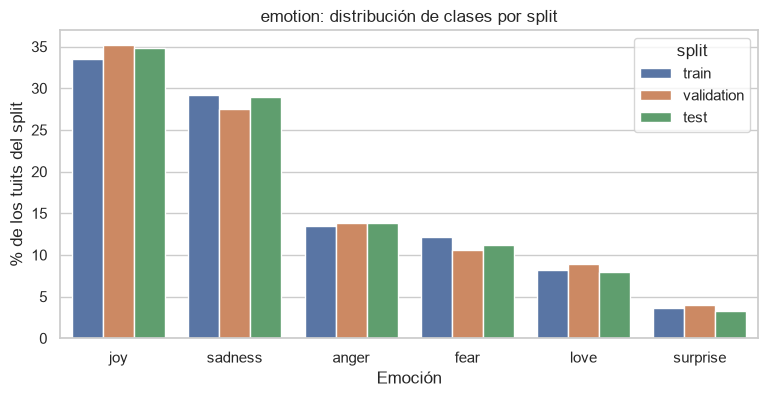

In [7]:
# Distribución de las 6 clases en cada split
conteos = pd.DataFrame({split: df["emocion"].value_counts() for split, df in df_emo.items()})
conteos = conteos.loc[conteos["train"].sort_values(ascending=False).index]
porcentajes = (conteos / conteos.sum() * 100).round(1)
display(conteos.join(porcentajes, rsuffix=" (%)"))
razon = conteos["train"].max() / conteos["train"].min()
print(f"En train, la clase más grande tiene {razon:.1f} veces más tuits que la más pequeña")

fig, ax = plt.subplots(figsize=(9, 4))
largo = porcentajes.reset_index(names="emoción").melt(
    id_vars="emoción", var_name="split", value_name="porcentaje"
)
sns.barplot(data=largo, x="emoción", y="porcentaje", hue="split", ax=ax)
ax.set(
    title="emotion: distribución de clases por split",
    xlabel="Emoción",
    ylabel="% de los tuits del split",
)
guardar(fig, "t1_distribucion_clases")
plt.show()

El dataset está desbalanceado. joy (33.5 %) y sadness (29.2 %) suman casi dos tercios del train, mientras que surprise tiene solo 572 tuits (3.6 %): la clase más grande tiene 9.4 veces más ejemplos que la más pequeña. Los tres splits tienen casi las mismas proporciones (ninguna clase cambia más de 1.7 puntos de un split a otro), así que validación y test se parecen al train.

In [8]:
# Tuits repetidos: dentro del train, con etiquetas distintas y entre splits
textos_train = set(train_emo[TEXT_COL])
etiquetas_por_texto = train_emo.groupby(TEXT_COL)["emocion"].agg(lambda e: sorted(set(e)))
conflictos = etiquetas_por_texto[etiquetas_por_texto.map(len) > 1]

print(f"Tuits repetidos dentro del train: {train_emo[TEXT_COL].duplicated().sum()}")
print(f"De esos, con etiquetas distintas: {len(conflictos)}")
for split in ["validation", "test"]:
    print(f"Tuits de {split} que también están en train: {df_emo[split][TEXT_COL].isin(textos_train).sum()}")

print("Pares de etiquetas en los repetidos:", conflictos.map(" / ".join).value_counts().to_dict())
display(conflictos.head(3).rename("etiquetas").to_frame())

Tuits repetidos dentro del train: 31
De esos, con etiquetas distintas: 30
Tuits de validation que también están en train: 5
Tuits de test que también están en train: 11
Pares de etiquetas en los repetidos: {'joy / love': 15, 'fear / surprise': 6, 'anger / fear': 4, 'anger / sadness': 3, 'joy / surprise': 1, 'fear / sadness': 1}


,etiquetas
text,
i am not amazing or great at photography but i feel passionate about it,"[joy, love]"
i began to feel accepted by gaia on her own terms,"[joy, love]"
i bet taylor swift basks in the knowledge that the boys she writes songs about probably feel tortured,"[anger, fear]"


Hay 31 tuits repetidos dentro del train y 30 de ellos tienen etiquetas distintas en cada copia. La mitad de esos casos son joy contra love (15) y les siguen fear contra surprise (6) y anger contra fear (4). Es una señal de que las etiquetas tienen ruido, lo que tiene sentido con una anotación automática por hashtags. Además, 5 tuits de validación y 11 de test también están en el train. Son menos del 1 % de cada split y no los quito, para que mis resultados se puedan comparar con los de otros trabajos que usan este dataset.

media  p50  p95  p99  máx
train      palabras   19.2   17   41   52   66
           tokens     22.3   20   45   57   87
validation palabras   18.9   17   40   52   61
           tokens     21.9   20   44   56   69
test       palabras   19.2   17   41   52   61
           tokens     22.2   20   45   55   66

Tuits con más de 64 tokens (los tres splits): 0.15%
Tuits con más de 128 tokens (los tres splits): 0.00%


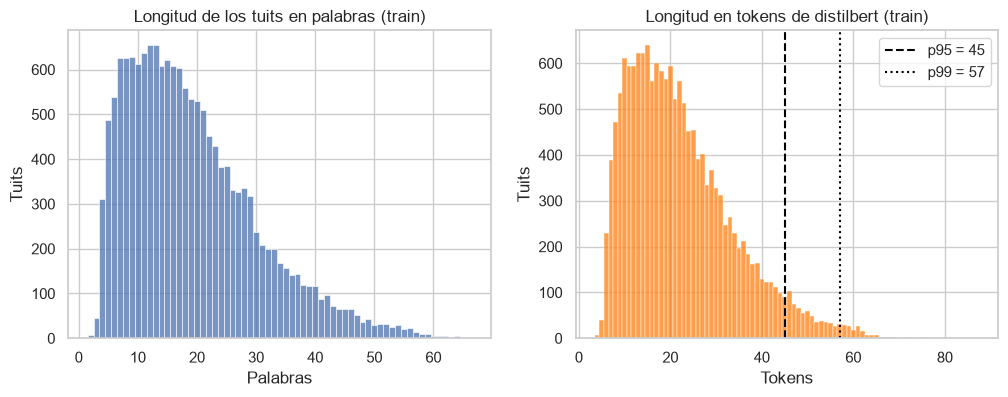

In [9]:
# Longitud de los tuits en palabras y en tokens de distilbert (solo el tokenizer, sin el modelo)
from transformers import AutoTokenizer

tok_emo = AutoTokenizer.from_pretrained(MODEL_ID)
for df in df_emo.values():
    df["palabras"] = df[TEXT_COL].str.split().str.len()
    # Sin truncar y con [CLS] y [SEP], que es lo que ve el modelo
    ids = tok_emo(df[TEXT_COL].tolist(), verbose=False)["input_ids"]
    df["tokens"] = [len(x) for x in ids]

display(tabla_longitudes(df_emo, ["palabras", "tokens"]))
todos = pd.concat(df_emo.values())
for limite in (64, 128):
    print(f"Tuits con más de {limite} tokens (los tres splits): {(todos['tokens'] > limite).mean():.2%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train_emo["palabras"], discrete=True, ax=axes[0])
axes[0].set(title="Longitud de los tuits en palabras (train)", xlabel="Palabras", ylabel="Tuits")
sns.histplot(train_emo["tokens"], discrete=True, ax=axes[1], color="tab:orange")
marcar_percentiles(axes[1], train_emo["tokens"])
axes[1].set(title="Longitud en tokens de distilbert (train)", xlabel="Tokens", ylabel="Tuits")
guardar(fig, "t1_longitudes")
plt.show()

Los tuits son cortos: 19 palabras y 22 tokens en promedio. El 95 % tiene 45 tokens o menos, el más largo tiene 87 y solo el 0.15 % pasa de 64. Ninguno llega a 128. Hay un poco más de tokens que de palabras porque se suman [CLS] y [SEP] y porque las palabras poco comunes se parten en subpalabras.

#### Qué implica para el entrenamiento

- max_length: uso `max_length=128`, con el que no se corta ningún tuit (el más largo tiene 87 tokens). Podría bajar a 64 y perder solo el 0.15 %, pero con padding dinámico (`DataCollatorWithPadding`) cada batch se rellena hasta su tuit más largo, así que el límite casi no cambia el costo.
- Métrica: la principal es F1 macro, que promedia el F1 de las seis clases con el mismo peso. Con un desbalance de 9.4 a 1, un modelo que nunca prediga surprise perdería apenas 3.6 puntos de accuracy, mientras que su F1 macro podría bajar hasta 16.7 puntos, porque esa clase pesa un sexto. El paper del dataset también usa F1 por el desbalance. Además reporto accuracy, el F1 de cada clase y la matriz de confusión.
- Desbalance: como los splits tienen las mismas proporciones, no hace falta repartirlos de nuevo. La muestra para la búsqueda de learning rate la saco estratificada por etiqueta, para que surprise no quede con muy pocos ejemplos. Primero entreno sin pesos por clase; si el F1 de surprise o de love queda muy bajo, pruebo pesos inversos a la frecuencia en la función de pérdida.
- Ruido: por los repetidos con etiquetas distintas, no espero llegar al 100 %, y es probable que el modelo confunda joy con love y fear con surprise. Eso lo reviso en la matriz de confusión.
- Modelo: el texto está en minúsculas, así que distilbert uncased no pierde información por no distinguir mayúsculas.

### 1.3 Búsqueda de hiperparámetros

### 1.4 Entrenamiento con la data completa

### 1.5 Evaluación del mejor modelo

## Tarea 2: Etiquetado de secuencias

Reconocer entidades nombradas en noticias en español con BETO (`bert-base-spanish-wwm-cased`).

In [10]:
# Tarea 2: constantes
DATASET_ID = "BramVanroy/conll2002"
DATASET_CONFIG = "es"
MODEL_ID = "dccuchile/bert-base-spanish-wwm-cased"

### 2.1 Descripción del dataset

El problema es reconocer entidades nombradas (NER) en noticias en español: encontrar en cada frase los nombres de personas, organizaciones, lugares y otras entidades. Sirve para sacar información estructurada de texto libre, por ejemplo para indexar noticias según las personas o empresas que mencionan.

- Entrada: una frase que ya viene separada en palabras (columna `tokens`).
- Salida: una etiqueta por palabra (columna `ner_tags`) en formato BIO, con cuatro tipos de entidad: PER (personas), ORG (organizaciones), LOC (lugares) y MISC (otras entidades). B- marca la primera palabra de una entidad, I- las siguientes y O las palabras que no son entidad. En total son 9 etiquetas.
- Tipo de problema: etiquetado de secuencias, o clasificación de tokens. Se clasifica cada palabra por separado, así que la salida tiene la misma longitud que la entrada.
- Tamaño: 8324 frases de train, 1916 de validación y 1518 de test. Son los archivos `train`, `testa` y `testb` del shared task original.
- Origen y anotación: es la parte en español del shared task CoNLL-2002. Son noticias de la agencia EFE de mayo de 2000. La anotación la hicieron el centro TALP de la Universidad Politécnica de Cataluña (UPC) y el CLiC de la Universidad de Barcelona (UB), con financiación del proyecto europeo NAMIC.
- `BramVanroy/conll2002` es una copia exacta de `eriktks/conll2002` en formato parquet. La original ya no carga con datasets 5 porque depende de un script.
- Licencia: según la card, no se sabe cuál es la licencia de los datos, en especial la del texto de las noticias ("unknown"). Lo uso solo con fines académicos.
- Cita: Tjong Kim Sang, E. F. (2002). Introduction to the CoNLL-2002 Shared Task: Language-Independent Named Entity Recognition. En *COLING-02: The 6th Conference on Natural Language Learning 2002 (CoNLL-2002)*. https://www.aclweb.org/anthology/W02-2024

El modelo es `dccuchile/bert-base-spanish-wwm-cased` (BETO), un BERT base de 110 M de parámetros preentrenado con texto en español. Uso la versión cased porque las mayúsculas ayudan a reconocer nombres propios. Su card reporta 88.43 de F1 en este dataset, medido sobre validación (el enlace del resultado apunta a un archivo `dev_results`). Con ese número voy a comparar mi resultado en validación.

In [11]:
# Carga del dataset y tamaño de cada split
from datasets import load_dataset

ds_ner = load_dataset(DATASET_ID, DATASET_CONFIG)
ETIQUETAS_NER = ds_ner["train"].features["ner_tags"].feature.names
ETIQUETAS_POS = ds_ner["train"].features["pos_tags"].feature.names

display(pd.DataFrame({"frases": {split: ds_ner[split].num_rows for split in ds_ner}}).T)
print("Columnas:", ds_ner["train"].column_names)
print("Etiquetas NER:", dict(enumerate(ETIQUETAS_NER)))

,train,validation,test
frases,8324,1916,1518


Columnas: ['id', 'tokens', 'pos_tags', 'ner_tags']
Etiquetas NER: {0: 'O', 1: 'B-PER', 2: 'I-PER', 3: 'B-ORG', 4: 'I-ORG', 5: 'B-LOC', 6: 'I-LOC', 7: 'B-MISC', 8: 'I-MISC'}


### 2.2 Análisis exploratorio (EDA)

In [12]:
# Funciones para pasar de etiquetas BIO a entidades
def entidades_bio(etiquetas):
    """Lista de (tipo, inicio, fin). Un I- sin B- antes también abre una entidad."""
    spans, tipo, inicio = [], None, None
    for i, et in enumerate([*etiquetas, "O"]):
        nueva = et.startswith("B-") or (et.startswith("I-") and et[2:] != tipo)
        if tipo is not None and (et == "O" or nueva):
            spans.append((tipo, inicio, i))
            tipo = None
        if nueva:
            tipo, inicio = et[2:], i
    return spans


def marcar_entidades(tokens, etiquetas):
    """Frase con las entidades entre corchetes, por ejemplo [PER Juan Pérez]."""
    spans = {inicio: (tipo, fin) for tipo, inicio, fin in entidades_bio(etiquetas)}
    partes, i = [], 0
    while i < len(tokens):
        if i in spans:
            tipo, fin = spans[i]
            partes.append(f"[{tipo} {' '.join(tokens[i:fin])}]")
            i = fin
        else:
            partes.append(tokens[i])
            i += 1
    return " ".join(partes)


df_ner = {}
for split in ds_ner:
    df = ds_ner[split].to_pandas()
    df["tokens"] = df["tokens"].map(list)
    df["etiquetas"] = df["ner_tags"].map(lambda ids: [ETIQUETAS_NER[i] for i in ids])
    df["pos"] = df["pos_tags"].map(lambda ids: [ETIQUETAS_POS[i] for i in ids])
    df_ner[split] = df
train_ner = df_ner["train"]

# Muchas "frases" son el encabezado de la noticia (ciudad, fecha y EFE)
encabezado = train_ner["tokens"].map(lambda t: "EFE" in t or "EFECOM" in t)
print(f"Frases de train que mencionan EFE o EFECOM (encabezados de noticia): {encabezado.mean():.1%}\n")

# Dos frases del train que no son encabezado, de 10 a 25 palabras y con al menos tres tipos de entidad
tipos = train_ner["etiquetas"].map(lambda ets: {t for t, _, _ in entidades_bio(ets)})
candidatas = train_ner[(tipos.map(len) >= 3) & train_ner["tokens"].map(len).between(10, 25) & ~encabezado]
muestra = candidatas.sample(2, random_state=SEED)
for _, fila in muestra.iterrows():
    print(marcar_entidades(fila["tokens"], fila["etiquetas"]), end="\n\n")

Frases de train que mencionan EFE o EFECOM (encabezados de noticia): 10.9%

[ORG Ecuality] está en [LOC Argentina] , [LOC Chile] , [LOC México] y [LOC Venezuela] con el nombre [MISC Alcosto] y en [LOC Brasil] y [LOC Portugal] con el dominio [MISC Superoferta.com] .

Pero la meta ulterior de [LOC Chade] para [PER Camacho] , hijo , es enfrentarlo al príncipe [PER Naseem Hamed] , quien reina en la [ORG OMB] .



In [13]:
# La primera frase palabra por palabra: una etiqueta NER por palabra.
# La fila "pos" es la columna pos_tags, que viene en el dataset pero no uso.
fila = muestra.iloc[0]
display(pd.DataFrame({"palabra": fila["tokens"], "ner": fila["etiquetas"], "pos": fila["pos"]}).T)
print(f"pos_tags tiene {len(ETIQUETAS_POS)} etiquetas gramaticales, por ejemplo {ETIQUETAS_POS[:8]}")

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
palabra,Ecuality,está,en,Argentina,",",Chile,",",México,y,Venezuela,con,el,nombre,Alcosto,y,en,Brasil,y,Portugal,con,el,dominio,Superoferta.com,.
ner,B-ORG,O,O,B-LOC,O,B-LOC,O,B-LOC,O,B-LOC,O,O,O,B-MISC,O,O,B-LOC,O,B-LOC,O,O,O,B-MISC,O
pos,NP,VMI,SP,NC,Fc,NC,Fc,AQ,CC,NC,SP,DA,NC,AQ,CC,SP,NC,CC,NC,SP,DA,NC,AQ,Fp


pos_tags tiene 60 etiquetas gramaticales, por ejemplo ['AO', 'AQ', 'CC', 'CS', 'DA', 'DE', 'DD', 'DI']


El 10.9 % de las frases de train son encabezados de noticia, como "La Coruña , 23 may ( EFECOM ) ." (el ejemplo que da la card), por eso escogí los ejemplos entre las que no lo son. Con los corchetes se ve que una entidad puede tener varias palabras, como [PER Naseem Hamed], y que MISC junta cosas variadas, como el nombre comercial Alcosto o el dominio Superoferta.com. En la tabla, la fila ner es lo que el modelo tiene que predecir: una etiqueta por palabra. La fila pos sale de la columna `pos_tags`, con 60 etiquetas gramaticales, que la card menciona como otra tarea posible con este dataset. En este proyecto solo uso `ner_tags`.

,train,validation,test,train (%),validation (%),test (%)
O,231920,45356,45355,87.61,85.70,88.01
B-PER,4321,1222,735,1.63,2.31,1.43
I-PER,3903,859,634,1.47,1.62,1.23
B-ORG,7390,1700,1400,2.79,3.21,2.72
I-ORG,4992,1366,1104,1.89,2.58,2.14
B-LOC,4913,984,1084,1.86,1.86,2.10
I-LOC,1891,337,325,0.71,0.64,0.63
B-MISC,2173,445,339,0.82,0.84,0.66
I-MISC,3212,654,557,1.21,1.24,1.08


,train,validation,test,train (%),validation (%),test (%)
ORG,7390,1700,1400,39.3,39.1,39.3
LOC,4914,985,1084,26.1,22.6,30.5
PER,4321,1222,735,23.0,28.1,20.7
MISC,2173,445,340,11.6,10.2,9.6


train      tokens O: 87.6 % | frases sin entidades: 25.5% | entidades por frase: 2.26 | I- sin B-: 1 | frases vacías: 1
validation tokens O: 85.7 % | frases sin entidades: 26.5% | entidades por frase: 2.27 | I- sin B-: 1 | frases vacías: 1
test       tokens O: 88.0 % | frases sin entidades: 21.7% | entidades por frase: 2.34 | I- sin B-: 1 | frases vacías: 1


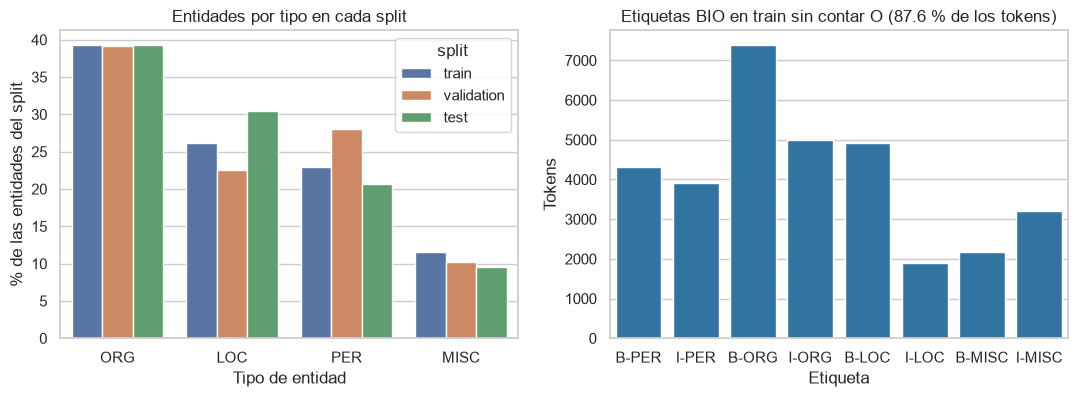

In [14]:
# Distribución de etiquetas BIO (con O) y de entidades por tipo en cada split
conteo_et = pd.DataFrame(
    {split: Counter(et for ets in df["etiquetas"] for et in ets) for split, df in df_ner.items()}
).reindex(ETIQUETAS_NER).fillna(0).astype(int)
pct_et = (conteo_et / conteo_et.sum() * 100).round(2)
display(conteo_et.join(pct_et, rsuffix=" (%)"))

conteo_ent = pd.DataFrame(
    {split: Counter(t for ets in df["etiquetas"] for t, _, _ in entidades_bio(ets)) for split, df in df_ner.items()}
)
conteo_ent = conteo_ent.loc[conteo_ent["train"].sort_values(ascending=False).index]
pct_ent = (conteo_ent / conteo_ent.sum() * 100).round(1)
display(conteo_ent.join(pct_ent, rsuffix=" (%)"))


def i_sin_b(ets):
    """Cuántas etiquetas I- no vienen después de una etiqueta del mismo tipo."""
    return sum(et.startswith("I-") and (i == 0 or ets[i - 1][2:] != et[2:]) for i, et in enumerate(ets))


for split, df in df_ner.items():
    n_ent = df["etiquetas"].map(lambda ets: len(entidades_bio(ets)))
    print(
        f"{split:<10} tokens O: {pct_et.loc['O', split]:.1f} % | frases sin entidades: {(n_ent == 0).mean():.1%}"
        f" | entidades por frase: {n_ent.mean():.2f} | I- sin B-: {df['etiquetas'].map(i_sin_b).sum()}"
        f" | frases vacías: {(df['tokens'].map(len) == 0).sum()}"
    )

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
largo = pct_ent.reset_index(names="tipo").melt(id_vars="tipo", var_name="split", value_name="porcentaje")
sns.barplot(data=largo, x="tipo", y="porcentaje", hue="split", ax=axes[0])
axes[0].set(title="Entidades por tipo en cada split", xlabel="Tipo de entidad", ylabel="% de las entidades del split")
sin_o = conteo_et["train"].drop(index="O")
sns.barplot(x=sin_o.index, y=sin_o.values, ax=axes[1], color="tab:blue")
axes[1].set(
    title=f"Etiquetas BIO en train sin contar O ({pct_et.loc['O', 'train']:.1f} % de los tokens)",
    xlabel="Etiqueta",
    ylabel="Tokens",
)
guardar(fig, "t2_distribucion_etiquetas")
plt.show()

El 87.6 % de los tokens de train son O: la gran mayoría de palabras no son parte de una entidad. Una de cada cuatro frases (25.5 %) no tiene ninguna entidad y en promedio hay 2.26 entidades por frase. ORG es el tipo más común en los tres splits (39 %) y MISC el más escaso (11.6 % en train). PER y LOC sí cambian de un split a otro: validación tiene más personas (28.1 %) y test más lugares (30.5 %) que train, así que el F1 de validación y el de test pueden no coincidir. El formato BIO está casi limpio, con una sola etiqueta I- sin su B- en cada split. También hay una frase vacía en cada split.

media  p50  p95  p99   máx
train      palabras    31.8   34   62   76  1238
           subtokens   39.8   42   74   92  3920
validation palabras    27.6   28   59   77   141
           subtokens   35.7   36   73   96   381
test       palabras    34.0   37   63   74   202
           subtokens   41.9   45   76   93   289

Subtokens por palabra (sin [CLS] ni [SEP]): 1.19
Frases con más de 64 subtokens (los tres splits): 1565 (13.31%)
Frases con más de 128 subtokens (los tres splits): 38 (0.32%)
Frases con más de 256 subtokens (los tres splits): 9 (0.08%)

La frase más larga de train tiene 1238 palabras y 160 entidades. Empieza así:
VALOR ANTER. MAX. MIN. ULTIMO % VAR VOLUMEN ULT PTA - ALIMENTACION ALTADIS 16.44 16.35 15.76 16.00 -2.68 2997037 2662 AZ.EBRO AGR. 13.25 13.59 13.01 13.55 2.26 28956 2255 EL AGUILA 7.79 7.77 7.60 7.77 -0.26 9934 1293 BARON DE LEY 23.15 23.68 [...]


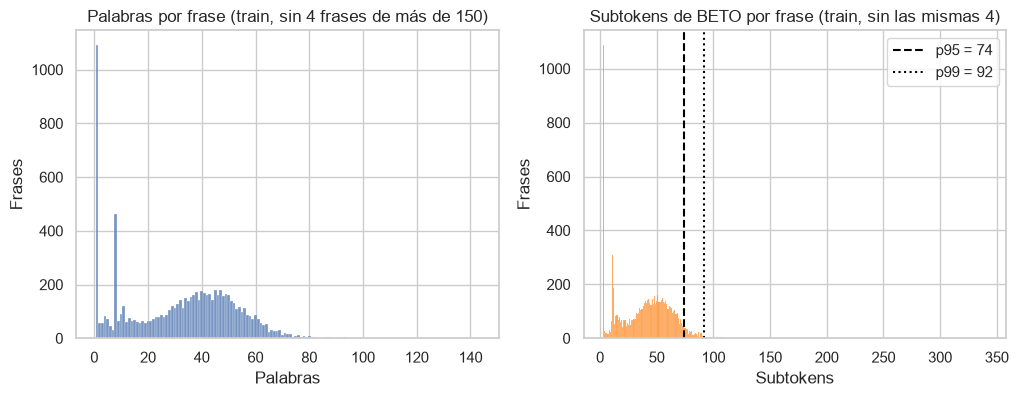

In [15]:
# Longitud de las frases en palabras y en subtokens de BETO (solo el tokenizer)
from transformers import AutoTokenizer

tok_ner = AutoTokenizer.from_pretrained(MODEL_ID)
for split, df in df_ner.items():
    df = df[df["tokens"].map(len) > 0].copy()  # quito la frase vacía de cada split
    df["palabras"] = df["tokens"].map(len)
    # Las palabras ya vienen separadas: is_split_into_words=True. Cuenta [CLS] y [SEP].
    ids = tok_ner(df["tokens"].tolist(), is_split_into_words=True, verbose=False)["input_ids"]
    df["subtokens"] = [len(x) for x in ids]
    df_ner[split] = df
train_ner = df_ner["train"]

display(tabla_longitudes(df_ner, ["palabras", "subtokens"]))
todos = pd.concat(df_ner.values())
print(f"Subtokens por palabra (sin [CLS] ni [SEP]): {(todos['subtokens'] - 2).sum() / todos['palabras'].sum():.2f}")
for limite in (64, 128, 256):
    print(f"Frases con más de {limite} subtokens (los tres splits): {(todos['subtokens'] > limite).sum()} ({(todos['subtokens'] > limite).mean():.2%})")

mas_larga = train_ner.loc[train_ner["palabras"].idxmax()]
print(f"\nLa frase más larga de train tiene {mas_larga['palabras']} palabras y "
      f"{len(entidades_bio(mas_larga['etiquetas']))} entidades. Empieza así:")
print(textwrap.shorten(" ".join(mas_larga["tokens"]), 250))

# En la gráfica dejo por fuera las pocas frases de más de 150 palabras para que se vea la forma
normales = train_ner[train_ner["palabras"] <= 150]
fuera = len(train_ner) - len(normales)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(normales["palabras"], discrete=True, ax=axes[0])
axes[0].set(title=f"Palabras por frase (train, sin {fuera} frases de más de 150)", xlabel="Palabras", ylabel="Frases")
sns.histplot(normales["subtokens"], discrete=True, ax=axes[1], color="tab:orange")
marcar_percentiles(axes[1], train_ner["subtokens"])
axes[1].set(title=f"Subtokens de BETO por frase (train, sin las mismas {fuera})", xlabel="Subtokens", ylabel="Frases")
guardar(fig, "t2_longitudes")
plt.show()

En train las frases tienen 32 palabras y 40 subtokens en promedio, y el 95 % tiene 74 subtokens o menos. BETO parte poco las palabras: 1.19 subtokens por palabra. Hay unas pocas frases muy largas, 38 pasan de 128 subtokens y 9 de 256. La más larga de train es en realidad una tabla de cotizaciones de la bolsa, con 1238 palabras, 3920 subtokens y 160 entidades. En validación la frase más larga tiene 381 subtokens y en test 289.

In [16]:
# Cómo parte BETO las palabras de la frase de ejemplo: las etiquetas son por palabra,
# así que al entrenar hay que decidir qué etiqueta recibe cada subtoken.
cod = tok_ner(fila["tokens"], is_split_into_words=True)
subtokens = cod.tokens()
por_palabra = {}
for pos, w in enumerate(cod.word_ids()):
    if w is not None:
        por_palabra.setdefault(w, []).append(subtokens[pos])
partidas = pd.DataFrame(
    {"palabra": fila["tokens"], "subtokens": [" ".join(por_palabra[i]) for i in range(len(fila["tokens"]))], "ner": fila["etiquetas"]}
)
display(partidas[partidas["subtokens"].str.contains(" ")])

,palabra,subtokens,ner
0,Ecuality,Ecu ##ali ##ty,B-ORG
13,Alcosto,Al ##cos ##to,B-MISC
22,Superoferta.com,Super ##of ##erta . com,B-MISC


En la frase de ejemplo, las únicas palabras que BETO parte son las entidades, que son nombres poco comunes: Ecuality queda como `Ecu ##ali ##ty` y Superoferta.com en cinco subtokens. Si le pongo la etiqueta solo al primer subtoken, `Ecu` recibe B-ORG y `##ali` y `##ty` quedan por fuera de la pérdida.

#### Qué implica para el entrenamiento

- max_length: en train uso `max_length=256`, que corta solo 9 frases de los tres splits (0.08 %), entre ellas la tabla de la bolsa. En validación y test no quiero dejar palabras sin predicción, así que ahí uso 512, el máximo de BETO, que alcanza para la frase más larga de cada split (381 y 289 subtokens). Con padding dinámico (`DataCollatorForTokenClassification`) el costo depende de la longitud real de cada batch, que en promedio es de 40 subtokens por frase.
- Etiquetas por subtoken: le pongo la etiqueta de la palabra al primer subtoken y -100 al resto, para que no cuenten ni en la pérdida ni en la evaluación. Con 1.19 subtokens por palabra, casi todas las palabras quedan con un solo subtoken.
- Limpieza: quito la frase vacía de cada split antes de tokenizar. Las tres etiquetas I- sin B- las dejo, porque seqeval las toma como inicio de entidad.
- Métrica: F1 de seqeval a nivel de entidad. Con 87.6 % de tokens O, un modelo que siempre diga O tendría 87.6 % de accuracy por token sin encontrar ninguna entidad. seqeval cuenta una entidad como acierto solo si el tipo y los límites coinciden con la referencia, que es como se evaluó el shared task. También reporto precisión, recall y F1 por tipo, para ver cómo le va a MISC, que es el tipo más escaso y el más variado. Mi punto de comparación es el 88.43 de F1 que reporta BETO en validación.
- Desbalance entre tipos: no uso pesos por clase. ORG tiene 3.4 veces más entidades que MISC, una diferencia moderada, y con el F1 por tipo veo si alguno se queda atrás.

### 2.3 Búsqueda de hiperparámetros

### 2.4 Entrenamiento con la data completa

### 2.5 Evaluación del mejor modelo

## Tarea 3: Sequence-to-sequence

Resumir diálogos en inglés con `bart-base`.

In [17]:
# Tarea 3: constantes
DATASET_ID = "knkarthick/dialogsum"
MODEL_ID = "facebook/bart-base"

### 3.1 Descripción del dataset

El problema es resumir conversaciones: a partir de un diálogo entre dos o más personas, generar un resumen corto de lo que pasó. Sirve para resumir reuniones, llamadas de servicio al cliente o chats largos.

- Entrada: el diálogo completo (columna `dialogue`), en inglés, con un turno por línea y los hablantes marcados como `#Person1#`, `#Person2#`, etc.
- Salida: el resumen (columna `summary`), un texto libre escrito por una persona. También hay una columna `topic` con el tema en pocas palabras, que no uso como salida.
- Tipo de problema: sequence-to-sequence, en concreto resumen abstractivo. El modelo tiene que redactar el resumen con sus propias palabras.
- Tamaño: 12460 diálogos de train, 500 de validación y 1500 filas de test. El test tiene 500 diálogos con tres resúmenes cada uno, lo que cuadra con los 13460 diálogos que menciona la card (12460 + 500 + 500).
- Origen y anotación: según la card, los diálogos salen de tres corpus públicos (DailyDialog, DREAM y MuTual) y de una página para practicar inglés hablado. Son conversaciones cara a cara sobre temas cotidianos como estudio, trabajo, salud, compras o viajes. Los resúmenes los escribieron expertos en lenguaje siguiendo unas reglas: dar la información más importante, ser breves, conservar las entidades nombradas, escribir desde el punto de vista de un observador y usar lenguaje formal.
- Licencia: CC BY-NC-SA 4.0 (uso no comercial, citando la fuente y compartiendo con la misma licencia).
- Cita: Chen, Y., Liu, Y., Chen, L. y Zhang, Y. (2021). DialogSum: A Real-Life Scenario Dialogue Summarization Dataset. En *Findings of the Association for Computational Linguistics: ACL-IJCNLP 2021*, pp. 5062-5074. https://aclanthology.org/2021.findings-acl.449

El modelo es `facebook/bart-base`, un encoder-decoder de 139 M de parámetros preentrenado en inglés a reconstruir texto al que le dañaron partes. Es del tipo BART que pide el enunciado para seq2seq y, en la prueba que hice para escoger modelo, funciona en fp16 sin problemas.

In [18]:
# Carga del dataset y tamaño de cada split
from datasets import load_dataset

ds_sum = load_dataset(DATASET_ID)
df_sum = {split: ds_sum[split].to_pandas() for split in ds_sum}

display(pd.DataFrame({
    "filas": {split: len(df) for split, df in df_sum.items()},
    "diálogos distintos": {split: df["dialogue"].nunique() for split, df in df_sum.items()},
}).T)
print("Columnas:", ds_sum["train"].column_names)

,train,validation,test
filas,12460,500,1500
diálogos distintos,12458,500,500


Columnas: ['id', 'dialogue', 'summary', 'topic']


### 3.2 Análisis exploratorio (EDA)

In [19]:
# Un ejemplo del train: diálogo, resumen y tema
def mostrar_dialogo(dialogo, ancho=110):
    for linea in dialogo.splitlines():
        print(textwrap.fill(linea, ancho, subsequent_indent="    "))


train_sum = df_sum["train"]
# Uno de largo típico: entre 8 y 12 líneas
tipicos = train_sum[train_sum["dialogue"].str.count("\n").between(7, 11)]
ej = tipicos.sample(1, random_state=SEED).iloc[0]
mostrar_dialogo(ej["dialogue"])
print("\nResumen:", textwrap.fill(ej["summary"], 110))
print("Tema:", ej["topic"])

#Person1#: How is your new car?
#Person2#: Perfect. Couldn't be better.
#Person1#: Why do you say so? Can I see your new car?
#Person2#: Of course you can. ( Lead Carl to his garage. )
#Person1#: Wow, this new car is dynamite! It is a shiny, beautiful car.
#Person2#: My car is simply a daisy. It drives smoothly.
#Person1#: The car has very sleek lines. I love it.
#Person2#: I am glad to hear that. I'm really pleased with it.
#Person1#: You made a good choice.

Resumen: #Person2# says #Person2#'s new car is perfect and shows #Person1# the car. #Person1# likes it.
Tema: a new car


Cada turno empieza con el hablante (`#Person1#`, `#Person2#`). El resumen es mucho más corto que el diálogo, está escrito desde afuera, en tercera persona, y nombra a los participantes con las mismas etiquetas `#Person1#` y `#Person2#` porque el diálogo no dice sus nombres. A veces el diálogo trae acotaciones entre paréntesis, como "( Lead Carl to his garage. )".

media  p50  p95  p99   máx
train      tokens_dialogo  212.4  193  390  579  1429
           tokens_resumen   36.9   34   65   84   249
validation tokens_dialogo  209.6  191  380  507   726
           tokens_resumen   34.7   32   62   80   100
test       tokens_dialogo  217.5  200  394  521  1366
           tokens_resumen   30.0   28   51   69   104

Diálogos con más de 256 tokens: 3758 (25.99%)
Diálogos con más de 512 tokens: 215 (1.49%)
Diálogos con más de 1024 tokens: 12 (0.08%)
Resúmenes con más de 64 tokens: 659 (4.56%)
Resúmenes con más de 96 tokens: 65 (0.45%)
Resúmenes con más de 128 tokens: 13 (0.09%)


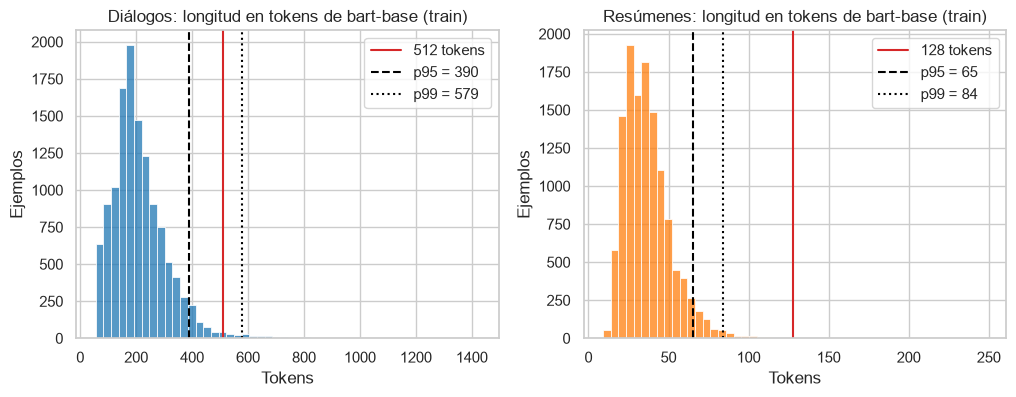

In [20]:
# Longitud de diálogos y resúmenes en tokens de bart-base (solo el tokenizer)
from transformers import AutoTokenizer

tok_sum = AutoTokenizer.from_pretrained(MODEL_ID)
for df in df_sum.values():
    # Sin truncar y con <s> y </s>
    df["tokens_dialogo"] = [len(x) for x in tok_sum(df["dialogue"].tolist(), verbose=False)["input_ids"]]
    df["tokens_resumen"] = [len(x) for x in tok_sum(df["summary"].tolist(), verbose=False)["input_ids"]]
    df["compresion"] = df["tokens_resumen"] / df["tokens_dialogo"]

display(tabla_longitudes(df_sum, ["tokens_dialogo", "tokens_resumen"]))
todos = pd.concat(df_sum.values())
for limite in (256, 512, 1024):
    print(f"Diálogos con más de {limite} tokens: {(todos['tokens_dialogo'] > limite).sum()} ({(todos['tokens_dialogo'] > limite).mean():.2%})")
for limite in (64, 96, 128):
    print(f"Resúmenes con más de {limite} tokens: {(todos['tokens_resumen'] > limite).sum()} ({(todos['tokens_resumen'] > limite).mean():.2%})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, titulo, color, limite in [
    (axes[0], "tokens_dialogo", "Diálogos", "tab:blue", 512),
    (axes[1], "tokens_resumen", "Resúmenes", "tab:orange", 128),
]:
    sns.histplot(train_sum[col], bins=50, ax=ax, color=color)
    ax.axvline(limite, color="tab:red", label=f"{limite} tokens")
    marcar_percentiles(ax, train_sum[col])
    ax.set(title=f"{titulo}: longitud en tokens de bart-base (train)", xlabel="Tokens", ylabel="Ejemplos")
guardar(fig, "t3_longitudes")
plt.show()

En train los diálogos tienen 212 tokens en promedio y los resúmenes 37. El 95 % de los diálogos tiene 390 tokens o menos, pero hay una cola larga: 215 diálogos de los tres splits (1.49 %) pasan de 512 tokens y 12 (0.08 %) pasan de 1024, que es lo máximo que acepta BART. De los resúmenes, solo 13 (0.09 %) pasan de 128 tokens. Los resúmenes del test son más cortos que los de train: 30 tokens en promedio contra 37.

,mean,std,min,5%,50%,95%,max
train,0.187,0.058,0.051,0.111,0.178,0.292,0.768
validation,0.179,0.061,0.069,0.105,0.169,0.272,0.776
test,0.154,0.056,0.031,0.085,0.142,0.268,0.448


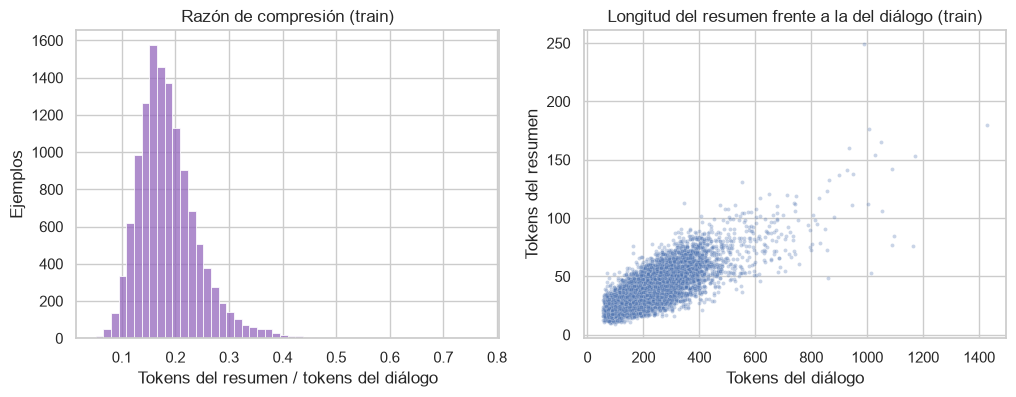

Correlación entre longitud del diálogo y del resumen (train): 0.79


In [21]:
# Cuánto se comprime: tokens del resumen / tokens del diálogo
compresion = pd.DataFrame({split: df["compresion"].describe(percentiles=[0.05, 0.5, 0.95]) for split, df in df_sum.items()})
display(compresion.T.drop(columns="count").round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train_sum["compresion"], bins=50, ax=axes[0], color="tab:purple")
axes[0].set(title="Razón de compresión (train)", xlabel="Tokens del resumen / tokens del diálogo", ylabel="Ejemplos")
sns.scatterplot(data=train_sum, x="tokens_dialogo", y="tokens_resumen", s=8, alpha=0.3, ax=axes[1])
axes[1].set(title="Longitud del resumen frente a la del diálogo (train)", xlabel="Tokens del diálogo", ylabel="Tokens del resumen")
guardar(fig, "t3_compresion")
plt.show()
print(f"Correlación entre longitud del diálogo y del resumen (train): {train_sum['tokens_dialogo'].corr(train_sum['tokens_resumen']):.2f}")

El resumen ocupa más o menos el 18 % de los tokens del diálogo (mediana de 0.178 en train) y su longitud crece con la del diálogo (correlación de 0.79). En test la razón es menor (mediana de 0.142), lo que cuadra con que sus resúmenes sean más cortos.

,,media,p50,p95,p99,máx
train,turnos,9.5,9,16,23,61
validation,turnos,9.4,9,16,20,29
test,turnos,9.7,9,16,26,65


Diálogos de train según número de hablantes: {2: 12333, 3: 113, 4: 9, 5: 3, 6: 1, 7: 1}
Resúmenes de train que nombran a alguien como #PersonN#: 88.3%
Así tokeniza bart-base un turno: ['#', 'Person', '1', '#', ':', 'ĠHello', ',', 'Ġhow', 'Ġare', 'Ġyou', '?']


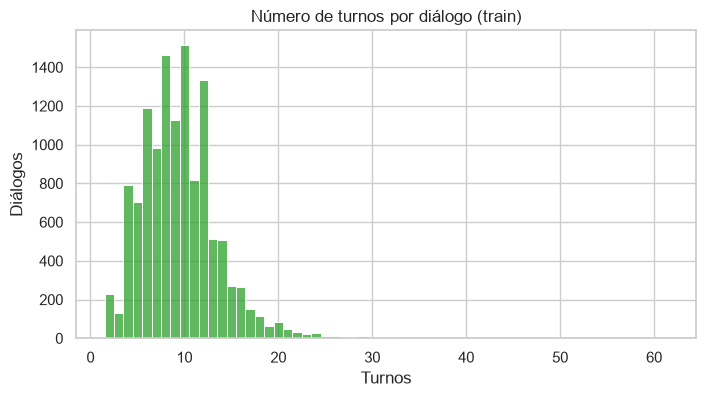

In [22]:
# Turnos y hablantes por diálogo
for df in df_sum.values():
    df["turnos"] = df["dialogue"].map(lambda d: sum(l.strip().startswith("#Person") for l in d.splitlines()))
    df["hablantes"] = df["dialogue"].str.findall(r"#Person\d+#").map(lambda h: len(set(h)))

display(tabla_longitudes(df_sum, ["turnos"]))
print("Diálogos de train según número de hablantes:", train_sum["hablantes"].value_counts().sort_index().to_dict())
print(f"Resúmenes de train que nombran a alguien como #PersonN#: {train_sum['summary'].str.contains('#Person').mean():.1%}")
print("Así tokeniza bart-base un turno:", tok_sum.tokenize("#Person1#: Hello, how are you?"))

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(train_sum["turnos"], discrete=True, ax=ax, color="tab:green")
ax.set(title="Número de turnos por diálogo (train)", xlabel="Turnos", ylabel="Diálogos")
guardar(fig, "t3_turnos")
plt.show()

Un diálogo tiene 9.5 turnos en promedio y casi todos son entre dos personas (12333 de 12460 en train). El 88.3 % de los resúmenes nombra a alguien como `#PersonN#`, así que el modelo tiene que aprender a escribir esas etiquetas. bart-base no las tiene como una sola pieza: `#Person1#` se parte en cuatro tokens (`#`, `Person`, `1`, `#`).

Temas distintos en train: 7187
Los 15 más comunes cubren el 9.0% de los diálogos
Temas que aparecen una sola vez: 5746


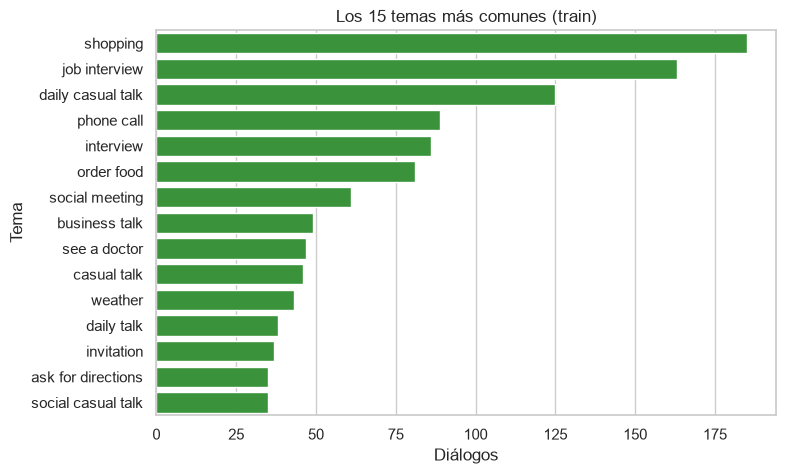

In [23]:
# Temas más comunes en train
temas = train_sum["topic"].str.strip().str.lower().value_counts()
top = temas.head(15)
print(f"Temas distintos en train: {len(temas)}")
print(f"Los 15 más comunes cubren el {top.sum() / len(train_sum):.1%} de los diálogos")
print(f"Temas que aparecen una sola vez: {(temas == 1).sum()}")

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=top.values, y=top.index, ax=ax, color="tab:green")
ax.set(title="Los 15 temas más comunes (train)", xlabel="Diálogos", ylabel="Tema")
guardar(fig, "t3_temas")
plt.show()

Los temas son texto libre y muy variados: hay 7187 temas distintos en train y 5746 aparecen una sola vez. Los 15 más comunes (compras, entrevistas de trabajo, charla casual, llamadas por teléfono...) cubren solo el 9 % de los diálogos, así que ningún tema domina el dataset.

In [24]:
# Un diálogo del test con sus 3 resúmenes. Los ids son test_<diálogo>_<1, 2 o 3>.
test_sum = df_sum["test"].copy()
test_sum["dialogo_id"] = test_sum["id"].str.rsplit("_", n=1).str[0]
grupos = test_sum.groupby("dialogo_id")
print(f"Diálogos en test: {grupos.ngroups}; resúmenes por diálogo: {grupos.size().value_counts().to_dict()}")
print(f"Grupos en los que las 3 filas tienen el mismo diálogo: {(grupos['dialogue'].nunique() == 1).mean():.0%}")
print(f"Grupos con los 3 temas distintos: {(grupos['topic'].nunique() == 3).sum()}")
textos_train = set(train_sum["dialogue"])
for split in ["validation", "test"]:
    print(f"Diálogos de {split} que también están en train: {df_sum[split]['dialogue'].isin(textos_train).sum()}")

ej_id = test_sum["dialogo_id"].drop_duplicates().sample(1, random_state=SEED).iloc[0]
grupo = grupos.get_group(ej_id)
print(f"\n{ej_id}\n")
mostrar_dialogo(grupo["dialogue"].iloc[0])
print()
for i, (_, r) in enumerate(grupo.iterrows(), 1):
    print(f"Resumen {i} ({r['tokens_resumen']} tokens, tema: {r['topic']}):")
    print(textwrap.fill(r["summary"], 110), end="\n\n")

Diálogos en test: 500; resúmenes por diálogo: {3: 500}
Grupos en los que las 3 filas tienen el mismo diálogo: 100%
Grupos con los 3 temas distintos: 350
Diálogos de validation que también están en train: 0
Diálogos de test que también están en train: 0

test_361

#Person1#: You're all set now?
#Person2#: Oh, thank you so much.
#Person1#: Really, it was nothing.
#Person2#: I really appreciated it.
#Person1#: I was happy to help.
#Person2#: It was so kind of you.
#Person1#: Don't mention it.
#Person2#: You're a real friend in need.

Resumen 1 (20 tokens, tema: gratitude):
#Person2# thanks #Person1# for #Person1#'s help.

Resumen 2 (18 tokens, tema: appreciation):
#Person2# appreciates for #Person1# 's kind help.

Resumen 3 (16 tokens, tema: appreciation):
#Person2# appreciates #Person1#'s help.



Los 500 diálogos del test tienen exactamente tres resúmenes cada uno, y las tres filas de cada grupo traen el mismo diálogo. Los resúmenes cuentan lo mismo con palabras distintas, como en este ejemplo ("thanks #Person1# for #Person1#'s help" frente a "appreciates #Person1#'s help"), y hasta el tema cambia: en 350 de los 500 diálogos los tres temas son distintos. Ningún diálogo de validación o de test aparece en train.

#### Qué implica para el entrenamiento

- max_source_length: uso 512 tokens para el diálogo, con lo que se corta el final del 1.49 % de los diálogos. Con 1024 solo se cortarían 12, pero cada batch que tenga uno de esos diálogos largos se vuelve mucho más caro. Si en la búsqueda de hiperparámetros veo que sobra tiempo, lo pruebo.
- max_target_length: 128 tokens para el resumen, que solo corta 13 resúmenes (0.09 %). Al generar uso el mismo límite; el resumen más largo del test tiene 104 tokens.
- Longitud de lo generado: el modelo aprende con los resúmenes de train, que son más largos que los del test, así que puede que genere resúmenes más largos que las referencias del test. Por eso reporto la longitud media de lo generado junto al ROUGE.
- Métrica: ROUGE-1, ROUGE-2, ROUGE-L y ROUGE-Lsum. ROUGE-1 y ROUGE-2 miden cuántas palabras y pares de palabras comparte el resumen generado con la referencia, y ROUGE-L mide la subsecuencia común más larga. En test genero una vez por diálogo (500) y comparo contra las tres referencias; el `rouge` de evaluate se queda con la que más se parece. Como tres personas resumen lo mismo con palabras distintas, comparar contra una sola referencia castigaría paráfrasis que están bien. Para ROUGE-Lsum separo las oraciones con saltos de línea.
- Etiquetas `#PersonN#`: no las agrego como tokens especiales. bart-base las parte en cuatro tokens que ya conoce, y el modelo puede aprender a copiarlas del diálogo.
- Validación: tiene 500 diálogos con una referencia cada uno. En la búsqueda de learning rate calculo ROUGE sobre 200 de ellos para no gastar mucho tiempo generando.

### 3.3 Búsqueda de hiperparámetros

### 3.4 Entrenamiento con la data completa

### 3.5 Evaluación del mejor modelo

## Conclusiones